# End-to-End Data Science Project: Predicting Term-Deposit Subscription in Retail Banking
**Domain:** BFSI | **Dataset:** UCI Bank Marketing (Moro, Cortez & Rita, 2014) | **Type:** Binary classification

**Real-world problem:** A bank's call centre contacts clients by phone to sell term deposits, but only
~11% of calls succeed. Can we (1) explain what drives success and (2) build a model that ranks clients so
calls are focused on the most promising ones, cutting wasted effort?

**Pipeline:** Data collection -> Cleaning -> EDA -> Hypothesis tests -> Statistical model (logistic
regression) -> Machine learning (CV + tuning) -> Business impact (lift analysis) -> Limitations.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from scipy.stats import randint
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
FIG, SEED = "../figures", 42
M = {}  # all headline metrics are stored here and exported to metrics.json for the report

## 1. Data Collection
The raw file (`bank_raw.csv`, 41,188 rows x 21 columns, semicolon-delimited) is the public UCI Bank Marketing
dataset (mirrored on GitHub). Each row is one phone contact with a client between May 2008 and Nov 2010.

In [2]:
raw = pd.read_csv("../data/bank_raw.csv", sep=";")
raw.columns = [c.replace(".", "_") for c in raw.columns]
M["raw_rows"], M["raw_cols"] = raw.shape
print(raw.shape); raw.head(3)

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Data Cleaning & Quality Assessment

In [3]:
M["n_missing_nan"] = int(raw.isna().sum().sum())
M["n_duplicates"] = int(raw.duplicated().sum())
cat_cols = raw.select_dtypes("object").columns
M["unknown_counts"] = {c: int((raw[c] == "unknown").sum()) for c in cat_cols if (raw[c] == "unknown").sum() > 0}
print("NaN:", M["n_missing_nan"], "| duplicates:", M["n_duplicates"]); print(M["unknown_counts"])

df = raw.drop_duplicates().reset_index(drop=True)
# default='yes' has 3 rows, all non-subscribers -> quasi-complete separation in logistic regression
M["default_yes_rows"] = int((df["default"] == "yes").sum())
df = df[df["default"] != "yes"].reset_index(drop=True)
df["was_previously_contacted"] = (df["pdays"] != 999).astype(int)   # 999 = sentinel for 'never contacted'
df["y_flag"] = (df["y"] == "yes").astype(int)
M["clean_rows"] = len(df); M["pos_rate"] = float(df.y_flag.mean())
df.to_csv("../data/bank_clean_final.csv", index=False)
print("Clean shape:", df.shape, "| positive rate:", round(M["pos_rate"], 4))

NaN: 0 | duplicates: 12
{'job': 330, 'marital': 80, 'education': 1731, 'default': 8597, 'housing': 990, 'loan': 990}


Clean shape: (41173, 23) | positive rate: 0.1127


**Cleaning decisions:** 12 duplicate rows removed; no true NaNs but several `unknown` categories kept as their
own level (non-disclosure can itself be informative); `pdays=999` converted to a binary flag; 3 records with
`default=yes` removed (separation); `duration` is **excluded from modelling** because it is only known after
the call ends (data leakage).

## 3. Exploratory Data Analysis

In [4]:
num_cols = ["age", "duration", "campaign", "previous", "emp_var_rate", "cons_price_idx",
            "cons_conf_idx", "euribor3m", "nr_employed"]
desc = df[num_cols].describe().T; desc["skew"] = df[num_cols].skew()
M["desc"] = desc.round(2).to_dict("index")
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
age,41173.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00,0.78
duration,41173.0,258.33,259.31,0.00,102.00,180.00,319.00,4918.00,3.26
campaign,41173.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00,4.76
previous,41173.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00,3.83
emp_var_rate,41173.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40,-0.72
cons_price_idx,41173.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77,-0.23
cons_conf_idx,41173.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90,0.30
euribor3m,41173.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04,-0.71
nr_employed,41173.0,5167.03,72.25,4963.60,5099.10,5191.00,5228.10,5228.10,-1.04


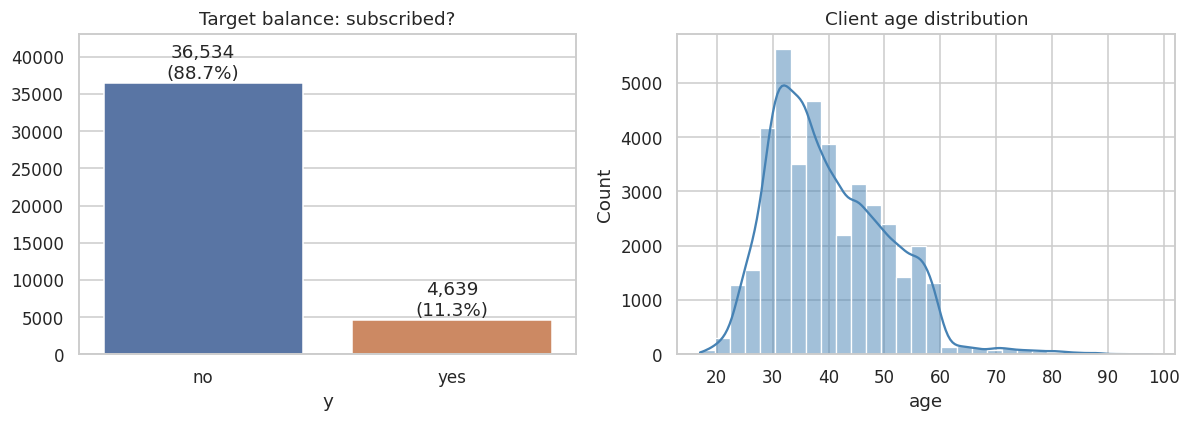

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
vc = df["y"].value_counts()
sns.barplot(x=vc.index, y=vc.values, ax=ax[0], palette=["#4C72B0", "#DD8452"])
for i, v in enumerate(vc.values): ax[0].text(i, v, f"{v:,}\n({100*v/len(df):.1f}%)", ha="center", va="bottom")
ax[0].set_title("Target balance: subscribed?"); ax[0].set_ylim(0, vc.max()*1.18)
sns.histplot(df["age"], bins=30, kde=True, ax=ax[1], color="steelblue"); ax[1].set_title("Client age distribution")
plt.tight_layout(); plt.savefig(f"{FIG}/01_target_and_age.png"); plt.show()

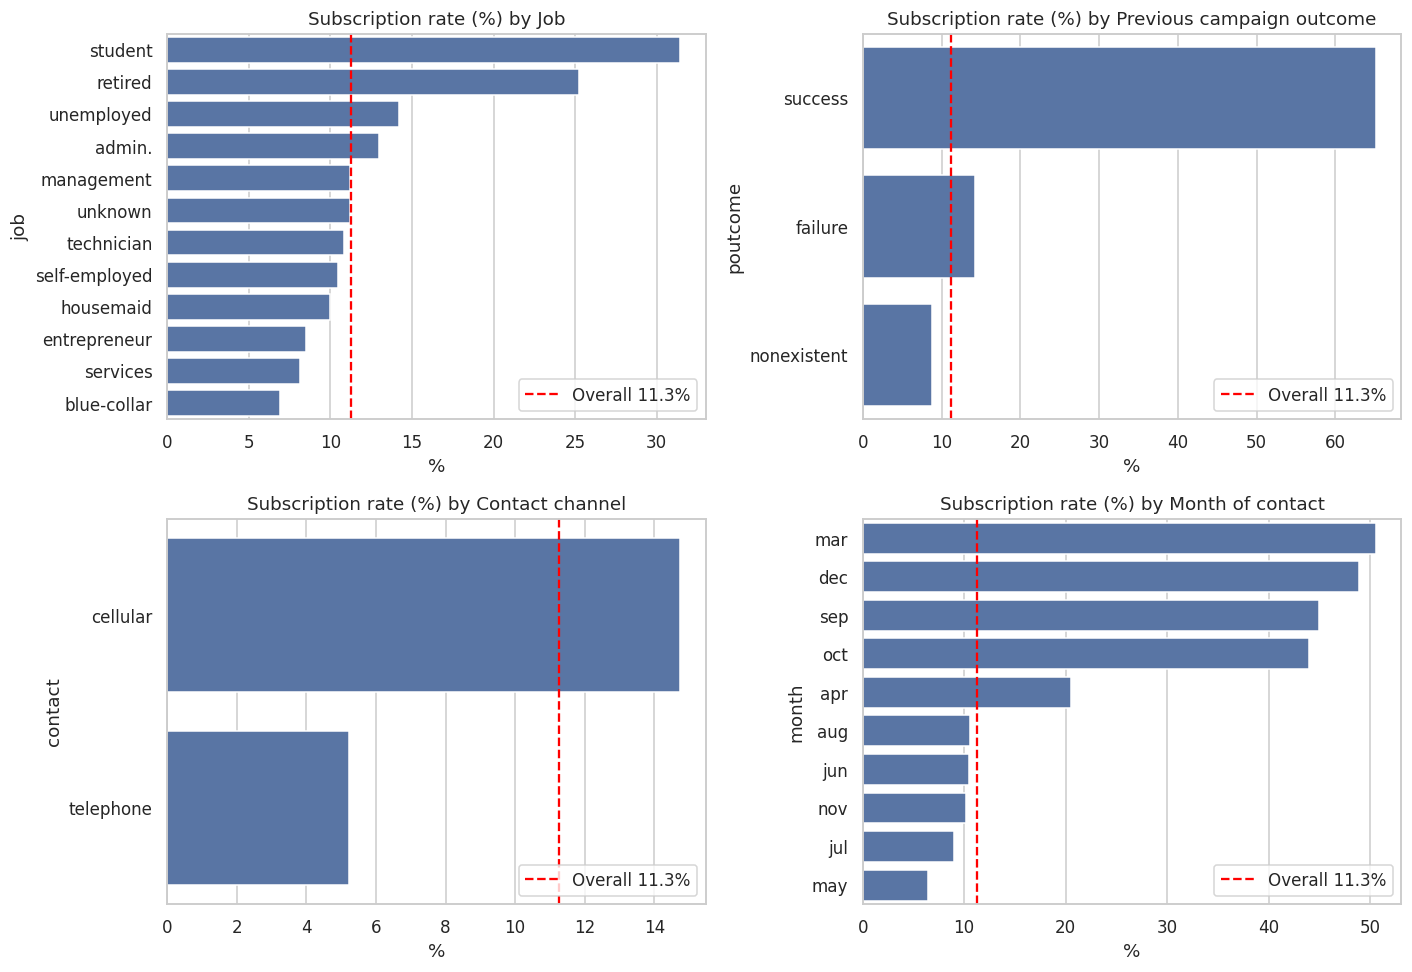

In [6]:
rates = {}
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, title) in zip(axes.ravel(), [("job", "Job"), ("poutcome", "Previous campaign outcome"),
                                          ("contact", "Contact channel"), ("month", "Month of contact")]):
    r = (df.groupby(col)["y_flag"].mean() * 100).sort_values(ascending=False)
    rates[col] = r.round(2).to_dict()
    sns.barplot(x=r.values, y=r.index, ax=ax, color="#4C72B0")
    ax.axvline(df.y_flag.mean()*100, color="red", ls="--", label="Overall 11.3%")
    ax.set_title(f"Subscription rate (%) by {title}"); ax.set_xlabel("%")
    ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{FIG}/02_subscription_rates.png"); plt.show()
M["rates"] = rates

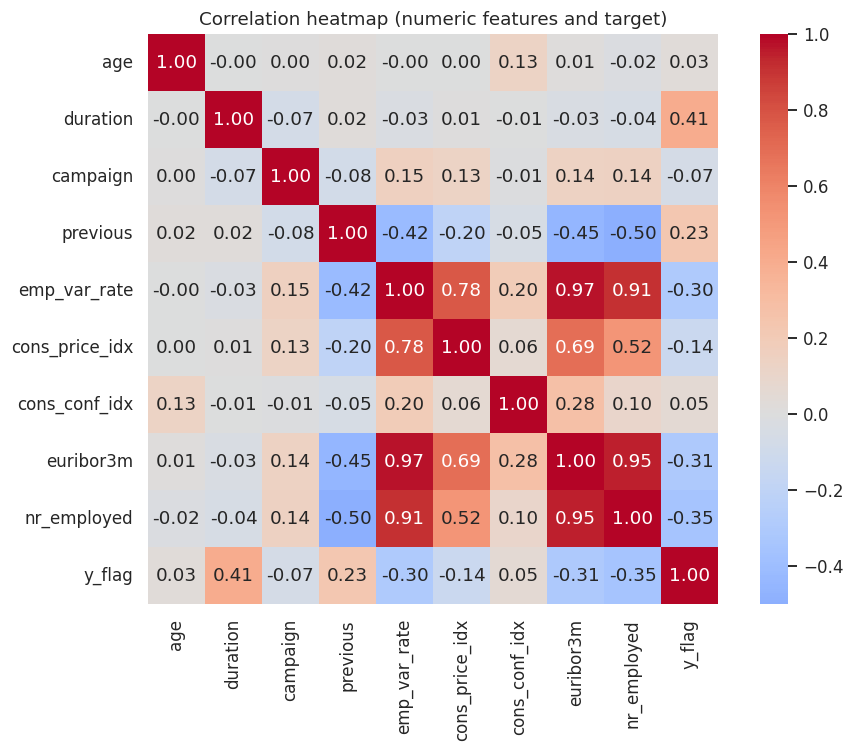

In [7]:
corr = df[num_cols + ["y_flag"]].corr()
M["corr_target"] = corr["y_flag"].round(3).to_dict()
M["corr_macro"] = {"emp_var_rate~euribor3m": round(corr.loc["emp_var_rate", "euribor3m"], 3),
                   "euribor3m~nr_employed": round(corr.loc["euribor3m", "nr_employed"], 3),
                   "emp_var_rate~nr_employed": round(corr.loc["emp_var_rate", "nr_employed"], 3)}
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation heatmap (numeric features and target)")
plt.tight_layout(); plt.savefig(f"{FIG}/03_correlation_heatmap.png"); plt.show()

## 4. Hypothesis Tests (univariate)

In [8]:
d1, d0 = df.loc[df.y_flag == 1, "duration"], df.loc[df.y_flag == 0, "duration"]
t, p = stats.ttest_ind(d1, d0, equal_var=False)
M["ttest_duration"] = dict(mean_yes=float(d1.mean()), mean_no=float(d0.mean()), t=float(t), p=float(p))
a1, a0 = df.loc[df.y_flag == 1, "age"], df.loc[df.y_flag == 0, "age"]
t2, p2 = stats.ttest_ind(a1, a0, equal_var=False)
M["ttest_age"] = dict(mean_yes=float(a1.mean()), mean_no=float(a0.mean()), t=float(t2), p=float(p2))
chi = {}
for c in ["poutcome", "job", "contact", "default", "education", "marital", "housing", "loan"]:
    c2, pc, dof, _ = stats.chi2_contingency(pd.crosstab(df[c], df["y"]))
    chi[c] = dict(chi2=float(c2), dof=int(dof), p=float(pc))
M["chi2"] = chi
print(M["ttest_duration"], M["ttest_age"]); pd.DataFrame(chi).T.round(4)

{'mean_yes': 553.2560896744989, 'mean_no': 220.8777303333881, 't': 55.49662880120091, 'p': 0.0} {'mean_yes': 40.91226557447726, 'mean_no': 39.91079542344118, 't': 4.776244316679159, 'p': 1.8345168024570337e-06}


,chi2,dof,p
poutcome,4229.8521,2.0,0.0000
job,961.7385,11.0,0.0000
contact,862.2968,1.0,0.0000
default,405.3768,1.0,0.0000
education,192.8309,7.0,0.0000
marital,122.8801,3.0,0.0000
housing,5.7328,2.0,0.0569
loan,1.1043,2.0,0.5757


## 5. Statistical Modelling — Logistic Regression (inference)
### 5.1 Multicollinearity: VIF, condition number and coefficient stability

In [9]:
base_num = ["age", "log_campaign", "previous", "cons_conf_idx"]
df["log_campaign"] = np.log1p(df["campaign"])
macro = ["emp_var_rate", "cons_price_idx", "euribor3m", "nr_employed"]
X_all = sm.add_constant(df[base_num + macro])
vif_all = {c: float(variance_inflation_factor(X_all.values, i)) for i, c in enumerate(X_all.columns) if c != "const"}
Xs = sm.add_constant(df[base_num + ["nr_employed"]])
vif_final = {c: float(variance_inflation_factor(Xs.values, i)) for i, c in enumerate(Xs.columns) if c != "const"}
zs = lambda d: (d - d.mean()) / d.std()
M["vif_all"], M["vif_final"] = vif_all, vif_final
M["cond_all"] = float(np.linalg.cond(zs(df[base_num + macro]).values))
M["cond_final"] = float(np.linalg.cond(zs(df[base_num + ["nr_employed"]]).values))
print("VIF all macro:", {k: round(v, 1) for k, v in vif_all.items()})
print("VIF final    :", {k: round(v, 2) for k, v in vif_final.items()})
print("Condition number all vs final:", round(M["cond_all"], 1), round(M["cond_final"], 1))

VIF all macro: {'age': 1.0, 'log_campaign': 1.0, 'previous': 1.3, 'cons_conf_idx': 2.6, 'emp_var_rate': 33.2, 'cons_price_idx': 6.3, 'euribor3m': 64.5, 'nr_employed': 31.6}
VIF final    : {'age': 1.02, 'log_campaign': 1.02, 'previous': 1.34, 'cons_conf_idx': 1.03, 'nr_employed': 1.37}
Condition number all vs final: 18.8 1.8


In [10]:
# Coefficient stability: fit logit with ALL four macro variables vs only nr_employed
cat_final = ["job", "marital", "education", "contact", "poutcome", "default"]
def fit_logit(num, cats):
    X = pd.get_dummies(df[num + cats], columns=cats, drop_first=True).astype(float)
    return sm.Logit(df["y_flag"], sm.add_constant(X)).fit(disp=0, maxiter=300)
m_all = fit_logit(base_num + macro, cat_final)
m_fin = fit_logit(base_num + ["nr_employed"], cat_final)
stab = {v: dict(all_coef=float(m_all.params[v]), all_se=float(m_all.bse[v]),
                fin_coef=float(m_fin.params.get(v, np.nan)), fin_se=float(m_fin.bse.get(v, np.nan)))
        for v in macro}
M["macro_stability"] = stab
M["ll_all"], M["ll_fin"] = float(m_all.llf), float(m_fin.llf)
M["aic_all"], M["aic_fin"] = float(m_all.aic), float(m_fin.aic)
pd.DataFrame(stab).T.round(4)

,all_coef,all_se,fin_coef,fin_se
emp_var_rate,-0.7183,0.0594,NaN,NaN
cons_price_idx,1.1839,0.0946,NaN,NaN
euribor3m,0.0061,0.0751,NaN,NaN
nr_employed,-0.0004,0.0013,-0.0103,0.0003


### 5.2 Final logistic model and hypothesis tests

In [11]:
m = m_fin
null = sm.Logit(df["y_flag"], np.ones(len(df))).fit(disp=0)
M["lr_stat"] = float(2 * (m.llf - null.llf)); M["lr_df"] = int(m.df_model)
M["lr_p"] = float(stats.chi2.sf(M["lr_stat"], m.df_model)); M["mcfadden"] = float(1 - m.llf / null.llf)
M["converged"] = bool(m.mle_retvals["converged"])
ci = np.exp(m.conf_int())
orr = pd.DataFrame({"coef": m.params, "OR": np.exp(m.params), "CI_lo": ci[0], "CI_hi": ci[1], "p": m.pvalues})
M["or_table"] = orr.round(5).to_dict("index")
print(M["converged"], round(M["lr_stat"], 1), round(M["mcfadden"], 3))
orr.loc[["age", "log_campaign", "previous", "cons_conf_idx", "nr_employed", "contact_telephone",
         "poutcome_success", "job_retired", "job_student", "job_blue-collar", "marital_single"]].round(4)

True 5612.5 0.194


,coef,OR,CI_lo,CI_hi,p
age,0.0022,1.0022,0.9981,1.0063,0.2902
log_campaign,-0.1817,0.8338,0.7697,0.9033,0.0000
previous,0.0698,1.0723,0.9697,1.1857,0.1738
cons_conf_idx,0.0214,1.0217,1.0154,1.0280,0.0000
nr_employed,-0.0103,0.9898,0.9893,0.9903,0.0000
contact_telephone,-0.6003,0.5487,0.5016,0.6001,0.0000
poutcome_success,1.8075,6.0952,5.2428,7.0863,0.0000
job_retired,0.3100,1.3634,1.1367,1.6353,0.0008
job_student,0.3037,1.3548,1.1166,1.6439,0.0021
job_blue-collar,-0.2265,0.7973,0.6982,0.9105,0.0008


### 5.3 Why is `age` significant alone but not in the full model?
Nested models: add blocks of covariates and watch the age odds-ratio and p-value.

                                           model      OR      lo      hi  \
0                                       Age only  1.0090  1.0061  1.0119   
1                                          + job  1.0040  1.0006  1.0074   
2                          + marital & education  1.0106  1.0068  1.0144   
3                   + contact, poutcome, default  1.0088  1.0048  1.0128   
4  + campaign, previous, confidence, nr_employed  1.0022  0.9981  1.0063   

        p  
0  0.0000  
1  0.0218  
2  0.0000  
3  0.0000  
4  0.2902  
62.0 25.9


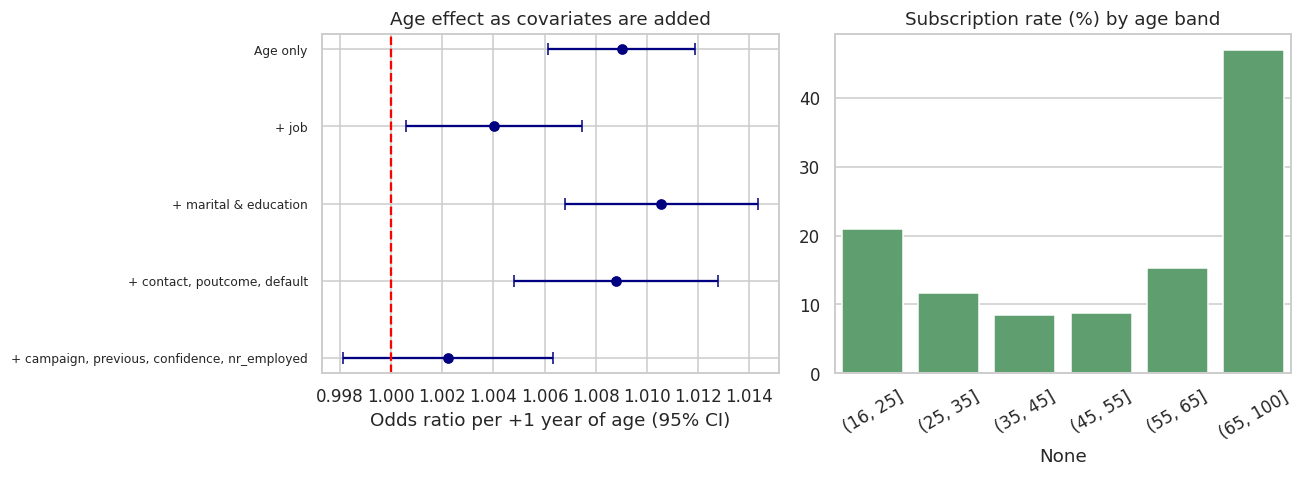

In [12]:
steps = [("Age only", [], []), ("+ job", [], ["job"]), ("+ marital & education", [], ["job", "marital", "education"]),
         ("+ contact, poutcome, default", [], cat_final), ("+ campaign, previous, confidence, nr_employed", base_num[1:] + ["nr_employed"], cat_final)]
age_path = []
for label, extra, cats in steps:
    mm = fit_logit(["age"] + extra, cats)
    ci_a = np.exp(mm.conf_int().loc["age"])
    age_path.append(dict(model=label, OR=float(np.exp(mm.params["age"])), lo=float(ci_a[0]), hi=float(ci_a[1]), p=float(mm.pvalues["age"])))
M["age_path"] = age_path
# age is mainly a proxy for life-stage: its relationship with job
M["age_by_job"] = df.groupby("job")["age"].mean().round(1).sort_values(ascending=False).to_dict()
M["sub_by_age_band"] = (df.groupby(pd.cut(df.age, [16, 25, 35, 45, 55, 65, 100]))["y_flag"].mean() * 100).round(2).astype(float).rename(str).to_dict()
print(pd.DataFrame(age_path).round(4)); print(M["age_by_job"]["retired"], M["age_by_job"]["student"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ap = pd.DataFrame(age_path)
ax[0].errorbar(ap["OR"], range(len(ap)), xerr=[ap["OR"] - ap["lo"], ap["hi"] - ap["OR"]], fmt="o", color="navy", capsize=4)
ax[0].axvline(1, color="red", ls="--"); ax[0].set_yticks(range(len(ap))); ax[0].set_yticklabels(ap["model"], fontsize=8)
ax[0].invert_yaxis(); ax[0].set_xlabel("Odds ratio per +1 year of age (95% CI)"); ax[0].set_title("Age effect as covariates are added")
bands = pd.Series(M["sub_by_age_band"])
sns.barplot(x=bands.index, y=bands.values, ax=ax[1], color="#55A868"); ax[1].set_title("Subscription rate (%) by age band")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{FIG}/04_age_effect_path.png"); plt.show()

### 5.4 Follow-up: what absorbs the age effect?
The nested path above is not monotonic (adding marital/education *raises* the age OR again), so "job explains age"
is only part of the story. Two further diagnostics: (a) the age-vs-subscription shape, (b) which late-added block removes it.

In [13]:
df["age_sq"] = ((df["age"] - df["age"].mean()) / df["age"].std()) ** 2
q = fit_logit(["age", "age_sq"], [])
M["age_quadratic"] = dict(p_age=float(q.pvalues["age"]), p_age_sq=float(q.pvalues["age_sq"]), coef_sq=float(q.params["age_sq"]))
m_age_macro = fit_logit(["age", "nr_employed"], [])
M["age_plus_macro"] = dict(OR=float(np.exp(m_age_macro.params["age"])), p=float(m_age_macro.pvalues["age"]))
M["corr_age_nr_employed"] = float(df[["age", "nr_employed"]].corr().iloc[0, 1])
M["mean_age_by_month"] = df.groupby("month")["age"].mean().round(1).to_dict()
M["n_by_month"] = df["month"].value_counts().to_dict()
print(M["age_quadratic"], M["age_plus_macro"], round(M["corr_age_nr_employed"], 3))

{'p_age': 4.772897331771752e-26, 'p_age_sq': 7.403839867755289e-170, 'coef_sq': 0.24592381658875695} {'OR': 1.0040441289636906, 'p': 0.0037376985623497902} -0.018


## 6. Machine Learning — model comparison, cross-validation, tuning
Stratified 75/25 split; the 25% test set is touched once at the end.

In [14]:
feat_num = ["age", "log_campaign", "previous", "emp_var_rate", "cons_price_idx", "cons_conf_idx",
            "euribor3m", "nr_employed", "was_previously_contacted"]
feat_cat = ["job", "marital", "education", "default", "contact", "month", "day_of_week", "poutcome"]
X = pd.get_dummies(df[feat_num + feat_cat], columns=feat_cat, drop_first=True).astype(float)
y = df["y_flag"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
sc = StandardScaler(); scale_cols = [c for c in feat_num if c != "was_previously_contacted"]
X_tr_s, X_te_s = X_tr.copy(), X_te.copy()
X_tr_s[scale_cols] = sc.fit_transform(X_tr[scale_cols]); X_te_s[scale_cols] = sc.transform(X_te[scale_cols])
M["n_train"], M["n_test"], M["n_features"] = len(X_tr), len(X_te), X.shape[1]

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
cands = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED), X_tr_s),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=SEED), X_tr),
    "Random Forest": (RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=SEED, n_jobs=-1), X_tr),
    "Hist. Gradient Boosting": (HistGradientBoostingClassifier(random_state=SEED), X_tr),
}
cvres = {}
for name, (mod, Xd) in cands.items():
    r = cross_validate(mod, Xd, y_tr, cv=cv, scoring=["roc_auc", "average_precision", "recall", "precision", "f1"], n_jobs=1)
    cvres[name] = {k.replace("test_", ""): (float(v.mean()), float(v.std())) for k, v in r.items() if k.startswith("test_")}
M["cv_baseline"] = cvres
print(pd.DataFrame({n: {k: f"{v[0]:.3f}+/-{v[1]:.3f}" for k, v in d.items()} for n, d in cvres.items()}).T)

                               roc_auc average_precision         recall  \
Logistic Regression      0.789+/-0.008     0.448+/-0.024  0.619+/-0.017   
Decision Tree            0.626+/-0.005     0.188+/-0.004  0.346+/-0.011   
Random Forest            0.764+/-0.009     0.389+/-0.020  0.288+/-0.012   
Hist. Gradient Boosting  0.797+/-0.011     0.466+/-0.020  0.253+/-0.017   

                             precision             f1  
Logistic Regression      0.353+/-0.010  0.450+/-0.012  
Decision Tree            0.313+/-0.006  0.329+/-0.007  
Random Forest            0.495+/-0.023  0.364+/-0.015  
Hist. Gradient Boosting  0.653+/-0.031  0.365+/-0.021  


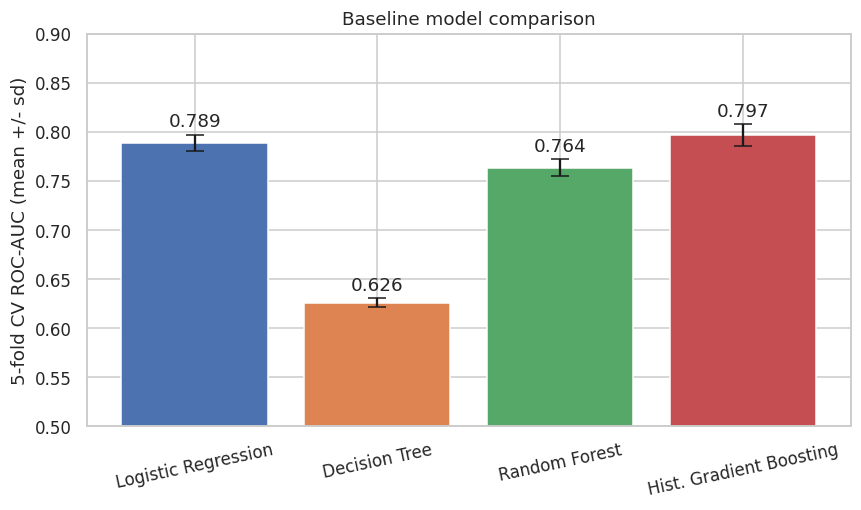

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.8))
names = list(cvres); mu = [cvres[n]["roc_auc"][0] for n in names]; sd = [cvres[n]["roc_auc"][1] for n in names]
ax.bar(names, mu, yerr=sd, capsize=6, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
for i, v in enumerate(mu): ax.text(i, v + sd[i] + 0.008, f"{v:.3f}", ha="center")
ax.set_ylim(0.5, 0.9); ax.set_ylabel("5-fold CV ROC-AUC (mean +/- sd)"); ax.set_title("Baseline model comparison")
plt.xticks(rotation=12); plt.tight_layout(); plt.savefig(f"{FIG}/05_model_comparison.png"); plt.show()

### 6.1 Hyper-parameter tuning (RandomizedSearchCV, 3-fold, ROC-AUC)

In [16]:
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
rf_space = {"n_estimators": randint(80, 160), "max_depth": randint(5, 16), "min_samples_leaf": randint(2, 25),
            "min_samples_split": randint(2, 20), "max_features": ["sqrt", 0.3], "class_weight": ["balanced", "balanced_subsample"]}
rf_s = RandomizedSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=-1), rf_space, n_iter=10, cv=cv3,
                          scoring="roc_auc", random_state=SEED, n_jobs=1).fit(X_tr, y_tr)
hgb_space = {"learning_rate": [0.03, 0.05, 0.08, 0.1], "max_depth": [3, 4, 6, None], "max_leaf_nodes": [15, 31, 63],
             "min_samples_leaf": [20, 50, 100], "l2_regularization": [0.0, 1.0, 5.0], "max_iter": [100, 200, 300]}
hgb_s = RandomizedSearchCV(HistGradientBoostingClassifier(random_state=SEED), hgb_space, n_iter=10, cv=cv3,
                           scoring="roc_auc", random_state=SEED, n_jobs=1).fit(X_tr, y_tr)
M["rf_best"] = dict(score=float(rf_s.best_score_), params={k: (v if isinstance(v, str) else float(v)) for k, v in rf_s.best_params_.items()})
M["hgb_best"] = dict(score=float(hgb_s.best_score_), params={k: (float(v) if v is not None else "None") for k, v in hgb_s.best_params_.items()})
print(M["rf_best"]); print(M["hgb_best"])

{'score': 0.7987604746921272, 'params': {'class_weight': 'balanced_subsample', 'max_depth': 9.0, 'max_features': 0.3, 'min_samples_leaf': 9.0, 'min_samples_split': 4.0, 'n_estimators': 101.0}}
{'score': 0.7973304445069074, 'params': {'min_samples_leaf': 20.0, 'max_leaf_nodes': 15.0, 'max_iter': 300.0, 'max_depth': 6.0, 'learning_rate': 0.05, 'l2_regularization': 5.0}}


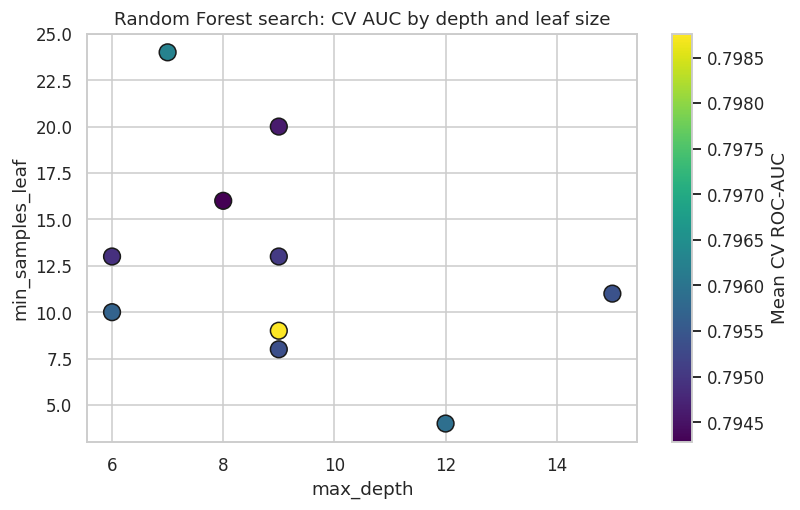

In [17]:
res = pd.DataFrame(rf_s.cv_results_)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
sc_ = ax.scatter(res["param_max_depth"].astype(int), res["param_min_samples_leaf"].astype(int), c=res["mean_test_score"],
                 cmap="viridis", s=120, edgecolor="k")
plt.colorbar(sc_, label="Mean CV ROC-AUC"); ax.set_xlabel("max_depth"); ax.set_ylabel("min_samples_leaf")
ax.set_title("Random Forest search: CV AUC by depth and leaf size")
plt.tight_layout(); plt.savefig(f"{FIG}/06_rf_tuning.png"); plt.show()
M["rf_search_range"] = [float(res.mean_test_score.min()), float(res.mean_test_score.max())]

### 6.2 Final evaluation on the untouched test set
The tuned model with the best CV ROC-AUC is chosen as the final model.

In [18]:
final_name, final = ("Hist. Gradient Boosting (tuned)", hgb_s.best_estimator_) if hgb_s.best_score_ >= rf_s.best_score_ \
    else ("Random Forest (tuned)", rf_s.best_estimator_)
M["final_name"] = final_name
rf_t = rf_s.best_estimator_.fit(X_tr, y_tr); hgb_t = hgb_s.best_estimator_.fit(X_tr, y_tr)
lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED).fit(X_tr_s, y_tr)
def evaluate(model, Xt, thr=0.5):
    pr = model.predict_proba(Xt)[:, 1]; pd_ = (pr >= thr).astype(int)
    cm = confusion_matrix(y_te, pd_); tn, fp, fn, tp = cm.ravel()
    return dict(acc=accuracy_score(y_te, pd_), prec=precision_score(y_te, pd_), rec=recall_score(y_te, pd_), f1=f1_score(y_te, pd_),
                auc=roc_auc_score(y_te, pr), ap=average_precision_score(y_te, pr), spec=tn/(tn+fp), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp)), pr
ev_lr, p_lr = evaluate(lr, X_te_s); ev_rf, p_rf = evaluate(rf_t, X_te); ev_hgb, p_hgb = evaluate(hgb_t, X_te)
M["test"] = {"Logistic Regression": ev_lr, "Random Forest (tuned)": ev_rf, "Hist. Gradient Boosting (tuned)": ev_hgb}
best_proba = p_hgb if final_name.startswith("Hist") else p_rf
ev_final = M["test"][final_name]
M["overfit"] = dict(train_auc=float(roc_auc_score(y_tr, final.predict_proba(X_tr)[:, 1])), test_auc=float(ev_final["auc"]))
print(pd.DataFrame(M["test"]).T.round(3)); print(M["overfit"])

                                   acc   prec    rec     f1    auc     ap  \
Logistic Regression              0.835  0.366  0.641  0.466  0.802  0.443   
Random Forest (tuned)            0.858  0.414  0.639  0.503  0.816  0.490   
Hist. Gradient Boosting (tuned)  0.901  0.674  0.237  0.351  0.812  0.484   

                                  spec      tn      fp     fn     tp  
Logistic Regression              0.859  7849.0  1285.0  417.0  743.0  
Random Forest (tuned)            0.885  8087.0  1047.0  419.0  741.0  
Hist. Gradient Boosting (tuned)  0.985  9001.0   133.0  885.0  275.0  
{'train_auc': 0.841620589018994, 'test_auc': 0.8157051524051857}


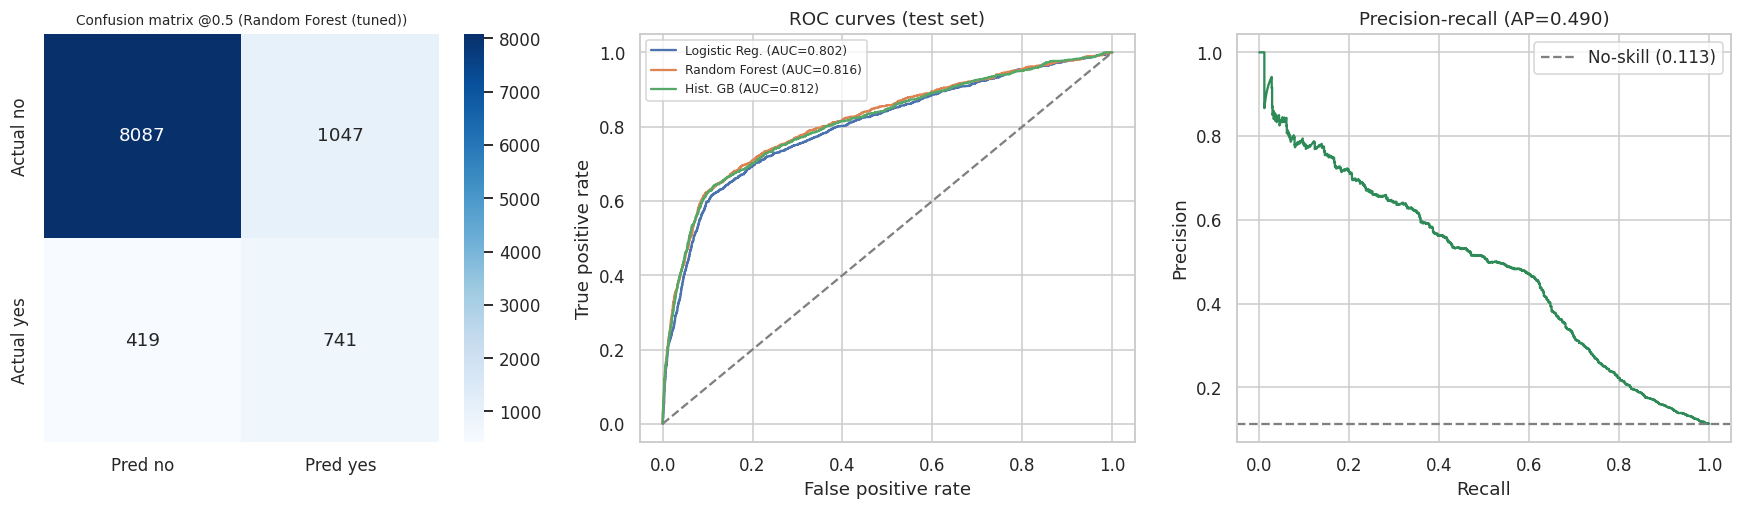

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
cm = np.array([[ev_final["tn"], ev_final["fp"]], [ev_final["fn"], ev_final["tp"]]])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0], xticklabels=["Pred no", "Pred yes"], yticklabels=["Actual no", "Actual yes"])
ax[0].set_title(f"Confusion matrix @0.5 ({final_name})", fontsize=9)
for nm, pr_ in [("Logistic Reg.", p_lr), ("Random Forest", p_rf), ("Hist. GB", p_hgb)]:
    f, t_, _ = roc_curve(y_te, pr_); ax[1].plot(f, t_, label=f"{nm} (AUC={roc_auc_score(y_te, pr_):.3f})")
ax[1].plot([0, 1], [0, 1], "--", color="gray"); ax[1].set_title("ROC curves (test set)"); ax[1].legend(fontsize=8)
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
pc, rc, _ = precision_recall_curve(y_te, best_proba)
ax[2].plot(rc, pc, color="seagreen"); ax[2].axhline(y_te.mean(), ls="--", color="gray", label=f"No-skill ({y_te.mean():.3f})")
ax[2].set_title(f"Precision-recall (AP={ev_final['ap']:.3f})"); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/07_test_evaluation.png"); plt.show()

### 6.3 Feature importance (permutation importance on the test set)

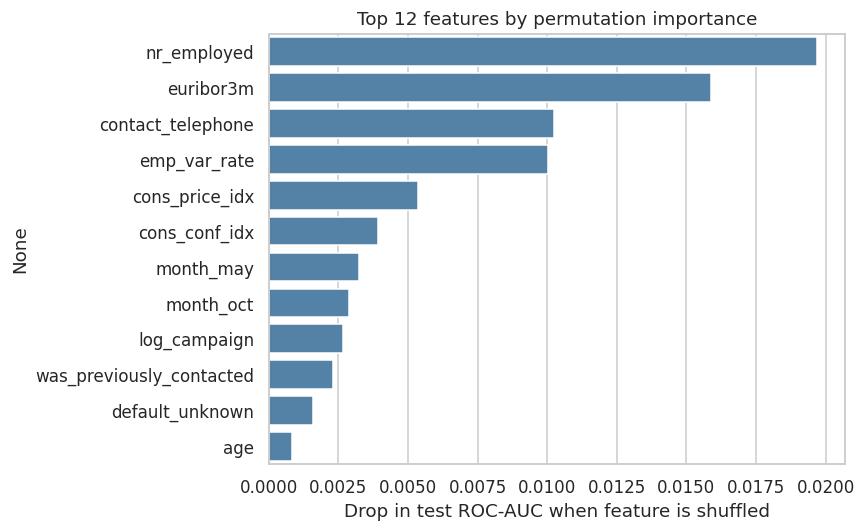

nr_employed                 0.0197
euribor3m                   0.0159
contact_telephone           0.0102
emp_var_rate                0.0100
cons_price_idx              0.0054
cons_conf_idx               0.0039
month_may                   0.0032
month_oct                   0.0029
log_campaign                0.0027
was_previously_contacted    0.0023
default_unknown             0.0016
age                         0.0008
dtype: float64

In [20]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(final, X_te, y_te, scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False).head(12)
M["perm_importance"] = imp.round(4).to_dict()
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, ax=ax, color="steelblue"); ax.set_xlabel("Drop in test ROC-AUC when feature is shuffled")
ax.set_title("Top 12 features by permutation importance")
plt.tight_layout(); plt.savefig(f"{FIG}/08_feature_importance.png"); plt.show(); imp.round(4)

### 6.4 Robustness check — temporal (out-of-time) split
The file is ordered chronologically (May 2008 -> Nov 2010) and the macro-economic features nearly identify the
calendar period, so a *random* split may be optimistic. Here the first 75% of rows train and the last 25% test.

In [21]:
cut = int(len(X) * 0.75)
Xa, Xb, ya, yb = X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:]
sc2 = StandardScaler(); Xa_s, Xb_s = Xa.copy(), Xb.copy()
Xa_s[scale_cols] = sc2.fit_transform(Xa[scale_cols]); Xb_s[scale_cols] = sc2.transform(Xb[scale_cols])
lr_t = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED).fit(Xa_s, ya)
rf_tt = RandomForestClassifier(**rf_s.best_params_, random_state=SEED, n_jobs=-1).fit(Xa, ya)
M["temporal"] = dict(train_n=int(len(Xa)), test_n=int(len(Xb)), train_pos=float(ya.mean()), test_pos=float(yb.mean()),
                     lr_auc=float(roc_auc_score(yb, lr_t.predict_proba(Xb_s)[:, 1])),
                     rf_auc=float(roc_auc_score(yb, rf_tt.predict_proba(Xb)[:, 1])),
                     rf_ap=float(average_precision_score(yb, rf_tt.predict_proba(Xb)[:, 1])))
print(M["temporal"])

{'train_n': 30879, 'test_n': 10294, 'train_pos': 0.06418601638654102, 'test_pos': 0.25811152127452885, 'lr_auc': 0.4303052572383848, 'rf_auc': 0.6312669747725513, 'rf_ap': 0.3408473340046679}


## 7. Business Impact — Gain / Lift analysis
If the call centre only phones the top-scored clients, what share of subscribers does it still reach?

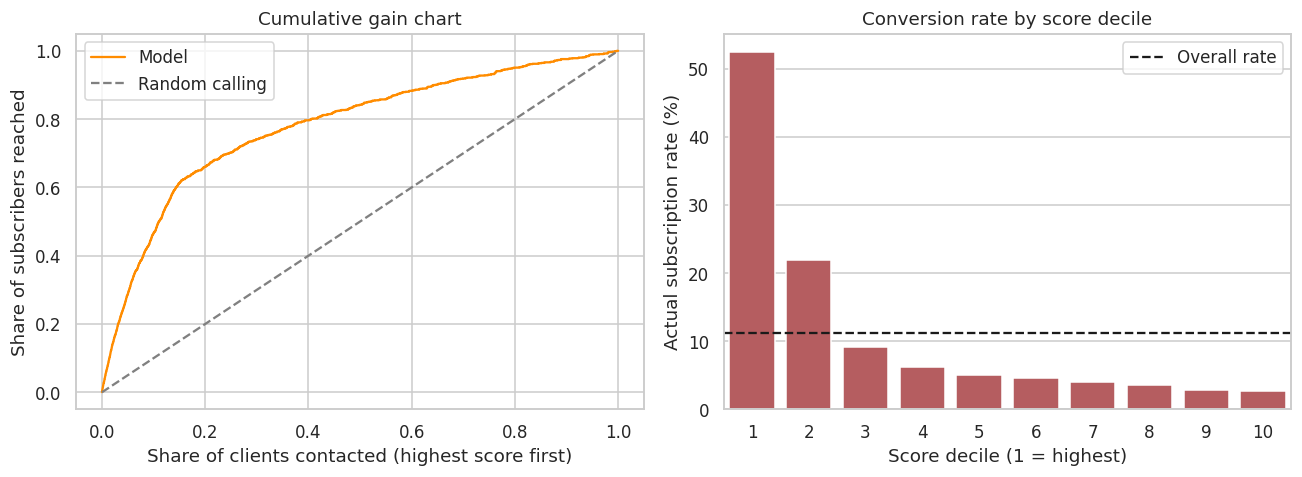

     captured   lift
10%     0.466  4.655
20%     0.660  3.302
30%     0.741  2.471
40%     0.797  1.991
50%     0.841  1.683


In [22]:
sc_df = pd.DataFrame({"y": y_te.values, "p": best_proba}).sort_values("p", ascending=False).reset_index(drop=True)
sc_df["cum_pos"] = sc_df["y"].cumsum() / sc_df["y"].sum()
fracs = [0.1, 0.2, 0.3, 0.4, 0.5]
gain = {}
for f in fracs:
    k = int(len(sc_df) * f); cap = float(sc_df["cum_pos"].iloc[k - 1]); gain[f"{int(f*100)}%"] = dict(captured=cap, lift=cap / f)
M["gain"] = gain
sc_df["decile"] = pd.qcut(sc_df.index, 10, labels=range(1, 11))
dec = sc_df.groupby("decile")["y"].mean() * 100
M["decile_rate"] = dec.round(2).astype(float).to_dict()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
xs = np.arange(1, len(sc_df) + 1) / len(sc_df)
ax[0].plot(xs, sc_df["cum_pos"], color="darkorange", label="Model"); ax[0].plot([0, 1], [0, 1], "--", color="gray", label="Random calling")
ax[0].set_xlabel("Share of clients contacted (highest score first)"); ax[0].set_ylabel("Share of subscribers reached")
ax[0].set_title("Cumulative gain chart"); ax[0].legend()
sns.barplot(x=[int(i) for i in dec.index], y=dec.values, ax=ax[1], color="#C44E52")
ax[1].axhline(y_te.mean()*100, ls="--", color="k", label="Overall rate"); ax[1].set_xlabel("Score decile (1 = highest)")
ax[1].set_ylabel("Actual subscription rate (%)"); ax[1].set_title("Conversion rate by score decile"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/09_gain_lift.png"); plt.show()
print(pd.DataFrame(gain).T.round(3))

In [23]:
with open("../metrics.json", "w") as f:
    json.dump(M, f, indent=1, default=str)
print("saved metrics.json")

saved metrics.json


## 8. Conclusions & Limitations
See the accompanying Word report for the full discussion. Key limitations: single bank / 2008-2010 era,
observational (association not causation), `unknown` categories not imputed, probabilities not calibrated,
modest tuning budget (10 random-search iterations per model, 3-fold) chosen for reproducibility on a single CPU.